In [1]:
import pandas as pd
from tensorflow.keras.preprocessing.text import Tokenizer

df = pd.read_csv('/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/dataSet/cold_intro_emails_dataset.csv')

/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
df.head()

,email
0,"Dear Mia,\n\nHope you're well and staying prod..."
1,"Dear Amelia,\n\nI hope you're doing well. I’m ..."
2,"Dear Charlotte,\n\nI hope this message finds y..."
3,"Dear Logan,\n\nHope you're well and staying pr..."
4,"Dear Sophia,\n\nHope you're having a great day..."


In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [4]:
texts = df['email'].astype(str).tolist()  

tokenizer = Tokenizer(filters='')
tokenizer.fit_on_texts(texts)
 
sequences = tokenizer.texts_to_sequences(texts)


In [5]:
#normalized texts

normalized_texts = [t.lower() for t in texts]

In [6]:
from cgitb import text

tokenizer_text=tokenizer.fit_on_texts(normalized_texts)

In [7]:
len(tokenizer.word_index)

379

In [8]:
input_sequences = []

for sentence in texts:  # texts is already a list of strings, no need to split
    tokenized_sentence = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(tokenized_sentence)):
        n_gram_sequence = tokenized_sentence[:i+1]
        input_sequences.append(n_gram_sequence)

In [9]:
max_len = max([len(x) for x in input_sequences])
max_len

80

In [10]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
padded_input_sequences = pad_sequences(input_sequences, maxlen = max_len, padding='pre')
padded_input_sequences

array([[  0,   0,   0, ...,   0,  17, 213],
       [  0,   0,   0, ...,  17, 213,   3],
       [  0,   0,   0, ..., 213,   3,  51],
       ...,
       [  0,   0,   0, ...,   2,  32, 166],
       [  0,   0,   0, ...,  32, 166, 217],
       [  0,   0,   0, ..., 166, 217, 379]], dtype=int32)

In [11]:
X = padded_input_sequences[:,:-1]

In [12]:
X.shape

(7319, 79)

In [13]:
y = padded_input_sequences[:,-1]

In [14]:
y.shape

(7319,)

In [15]:
y.shape

(7319,)

In [16]:
num_classes = y.max() - 1 

In [17]:
import numpy as np
print("min label:", y.min())
print("max label:", y.max())


min label: 1
max label: 379


In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, GRU, Dense, Dropout, SimpleRNN

model = Sequential()
model.add(Embedding(input_dim=20, output_dim=20, input_length=max_len-1))
model.add(SimpleRNN(units=16, return_sequences=False,recurrent_dropout=0.0))
model.add(Dropout(0.5))
model.add(Dense(8, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.build(input_shape=(None, max_len-1))
model.summary()

/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/lib/python3.9/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
2025-08-26 10:35:27.924453: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2025-08-26 10:35:27.924626: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-08-26 10:35:27.924640: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-08-26 10:35:27.924844: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-08-26 10:35:27.924858: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus i

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 79, 20)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,128 (4.41 KB)

 Trainable params: 1,128 (4.41 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [ ]:
history = model.fit(X,y,epochs=10 , callbacks=[early_stop],validation_split=0.02)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 466s 2s/step - accuracy: 0.0313 - loss: 0.5048 - val_accuracy: 0.0204 - val_loss: 0.3654
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 508s 2s/step - accuracy: 0.0250 - loss: 0.4984 - val_accuracy: 0.0204 - val_loss: 0.3595
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 513s 2s/step - accuracy: 0.0265 - loss: 0.5079 - val_accuracy: 0.0204 - val_loss: 0.3571
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 539s 2s/step - accuracy: 0.0252 - loss: 0.4843 - val_accuracy: 0.0204 - val_loss: 0.3555
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 545s 2s/step - accuracy: 0.0288 - loss: 0.4933 - val_accuracy: 0.0204 - val_loss: 0.3541
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 509s 2s/step - accuracy: 0.0291 - loss: 0.4840 - val_accuracy: 0.0204 - val_loss: 0.3522
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 542s 2s/step - accuracy: 0.0245 - loss: 0.4671 - val_accuracy: 0.0204 - val_loss: 0.3520
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 529s 2s/step - accuracy: 0.0274 - loss: 0.4656 - val_accu

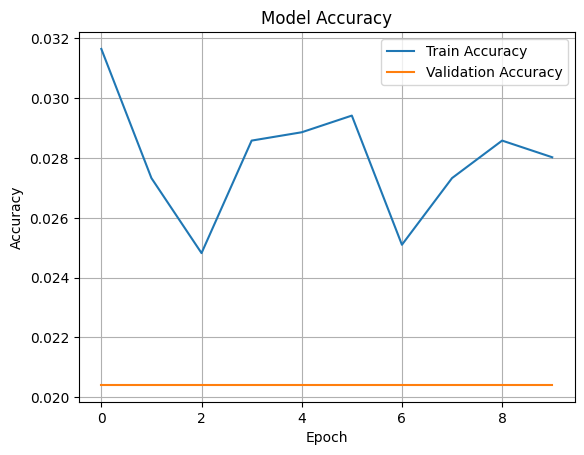

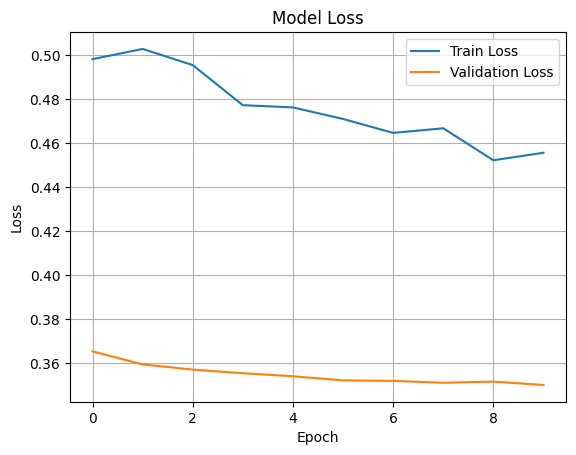

In [22]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# random 

import time
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

text = "Hello Rahul"
generated_text = text

print("\nGenerated Email:\n")
print(text, end=" ", flush=True)

for _ in range(63):
    token_text = tokenizer.texts_to_sequences([generated_text])[0]
    padded_token_text = pad_sequences([token_text], maxlen=56, padding='pre')

    prediction = model.predict(padded_token_text, verbose=0)[0]

    prediction = prediction / np.sum(prediction)
   
    next_index = np.random.choice(len(prediction), p=prediction)

    predicted_word = next((word for word, index in tokenizer.word_index.items() if index == next_index), None)

    if predicted_word is None:
        break

    print(predicted_word, end=" ", flush=True)
    generated_text += " " + predicted_word

print("\n\nBest regards,\nBimal Thapa")


Generated Email:

Hello Rahul 

Best regards,
Bimal Thapa
